# Image dataset: k-NN

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from models.knn import KNN
from utils.data import load_train
from utils.evaluation import evaluate, print_report, get_confusion_matrix
from utils.preprocessing import make_preprocessor

X, y = load_train("image")
X, y = np.asarray(X), np.asarray(y)

# 80% to train on, 20% to validate on
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, " Validation:", X_val.shape,
      " Classes:", len(np.unique(y)))

Train: (16000, 500)  Validation: (4000, 500)  Classes: 50


## Preprocessing

Scaling the features before measuring distances

In [2]:
rows = []
best_score = 0

for preprocessing in ["none", "standard", "sqrt_l2"]:
    prep = make_preprocessor(preprocessing)
    Xtr = prep.fit_transform(X_train, y_train)
    Xv = prep.transform(X_val)

    model = KNN(k=5, distance="euclidean")
    model.fit(Xtr, y_train)

    metrics = evaluate(y_val, model.predict(Xv))
    rows.append({"preprocessing": preprocessing, **metrics})

    if metrics["accuracy"] > best_score:
        best_score, best_preprocessing = metrics["accuracy"], preprocessing

display(pd.DataFrame(rows))
print("Kept preprocessing =", best_preprocessing)

# Every later step uses the data prepared with the best preprocessing
prep = make_preprocessor(best_preprocessing)
Xtr = prep.fit_transform(X_train, y_train)
Xv = prep.transform(X_val)

,preprocessing,accuracy,macro_f1
0,none,0.42000,0.418829
1,standard,0.31725,0.331719
2,sqrt_l2,0.44925,0.453074


Kept preprocessing = sqrt_l2


## Number of neighbours (k)

How many nearest training images vote on the label

In [3]:
rows = []
best_score = 0

for k in [1, 3, 5, 11]:
    model = KNN(k=k, distance="euclidean")
    model.fit(Xtr, y_train)

    metrics = evaluate(y_val, model.predict(Xv))
    rows.append({"k": k, **metrics})

    if metrics["accuracy"] > best_score:
        best_score, best_k = metrics["accuracy"], k

display(pd.DataFrame(rows))
print("Kept k =", best_k)

,k,accuracy,macro_f1
0,1,0.57200,0.570930
1,3,0.44675,0.446611
2,5,0.44925,0.453074
3,11,0.42450,0.421231


Kept k = 1


## Distance

How closeness between two images is measured. The density penalty in the next step only works with cosine.

In [4]:
rows = []

for distance in ["euclidean", "cosine"]:
    model = KNN(k=best_k, distance=distance)
    model.fit(Xtr, y_train)

    metrics = evaluate(y_val, model.predict(Xv))
    rows.append({"distance": distance, **metrics})

display(pd.DataFrame(rows))

,distance,accuracy,macro_f1
0,euclidean,0.57200,0.570930
1,cosine,0.57175,0.570668


## Density penalty

Lowers the score of training images that look similar to everything, so they stop winning by default

In [5]:
rows = []
best_score = 0

for density_penalty in [0, 0.3, 0.5, 0.7, 1.0]:
    model = KNN(k=best_k, distance="cosine",
                density_penalty=density_penalty, density_neighbors=20)
    model.fit(Xtr, y_train)

    metrics = evaluate(y_val, model.predict(Xv))
    rows.append({"density_penalty": density_penalty, **metrics})

    if metrics["accuracy"] > best_score:
        best_score, best_density_penalty = metrics["accuracy"], density_penalty

display(pd.DataFrame(rows))
print("Kept density_penalty =", best_density_penalty)

,density_penalty,accuracy,macro_f1
0,0.0,0.57175,0.570668
1,0.3,0.60325,0.602202
2,0.5,0.61550,0.614220
3,0.7,0.60950,0.608599
4,1.0,0.58575,0.585578


Kept density_penalty = 0.5


## Density neighbours

How many neighbours are used to measure how crowded each training image is

In [6]:
rows = []
best_score = 0

for density_neighbors in [10, 20, 50]:
    model = KNN(k=best_k, distance="cosine",
                density_penalty=best_density_penalty,
                density_neighbors=density_neighbors)
    model.fit(Xtr, y_train)

    metrics = evaluate(y_val, model.predict(Xv))
    rows.append({"density_neighbors": density_neighbors, **metrics})

    if metrics["accuracy"] > best_score:
        best_score, best_density_neighbors = metrics["accuracy"], density_neighbors

display(pd.DataFrame(rows))
print("Kept density_neighbors =", best_density_neighbors)

,density_neighbors,accuracy,macro_f1
0,10,0.61175,0.611070
1,20,0.61550,0.614220
2,50,0.61275,0.611389


Kept density_neighbors = 20


## Final Model

The hyperparameters we reached and their scores.

preprocessing: sqrt_l2  k: 1  distance: cosine  density_penalty: 0.5  density_neighbors: 20
{'accuracy': 0.6155, 'macro_f1': 0.6142204001404887}
              precision    recall  f1-score   support

           0       0.61      0.59      0.60        80
           1       0.57      0.60      0.59        80
           2       0.65      0.69      0.67        80
           3       0.67      0.59      0.63        80
           4       0.69      0.71      0.70        80
           5       0.68      0.74      0.71        80
           6       0.49      0.51      0.50        80
           7       0.56      0.69      0.61        80
           8       0.50      0.56      0.53        80
           9       0.52      0.45      0.48        80
          10       0.59      0.46      0.52        80
          11       0.66      0.59      0.62        80
          12       0.67      0.80      0.73        80
          13       0.67      0.69      0.68        80
          14       0.64      0.57      0.61 

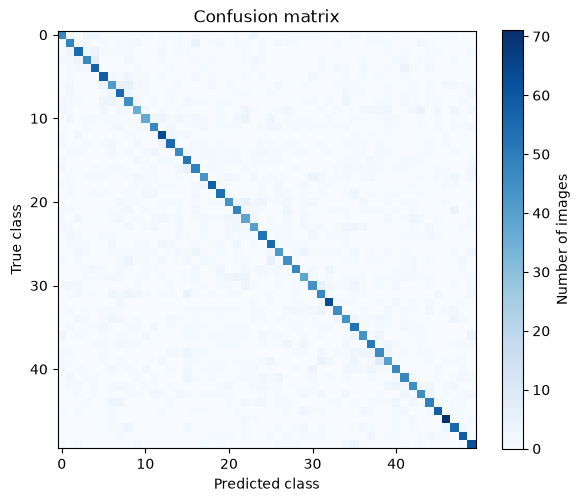

In [7]:
print("preprocessing:", best_preprocessing, " k:", best_k, " distance: cosine",
      " density_penalty:", best_density_penalty,
      " density_neighbors:", best_density_neighbors)

model = KNN(k=best_k, distance="cosine",
            density_penalty=best_density_penalty,
            density_neighbors=best_density_neighbors)
model.fit(Xtr, y_train)

val_predictions = model.predict(Xv)
print(evaluate(y_val, val_predictions))
print_report(y_val, val_predictions)

# 50 classes: the confusion matrix is shown as a picture instead of a table
labels = np.unique(y_val)
matrix = get_confusion_matrix(y_val, val_predictions, labels=labels)

plt.figure(figsize=(6, 5))
plt.imshow(matrix, cmap="Blues")
plt.colorbar(label="Number of images")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()

## Submission model

The hyperparams that we settled for the submission after testing our highest score

In [8]:
prep = make_preprocessor("sqrt_l2")
Xtr_final = prep.fit_transform(X_train, y_train)
Xv_final = prep.transform(X_val)

final_model = KNN(
    k=1,
    distance="cosine",
    density_penalty=0.5,
    density_neighbors=20,
)
final_model.fit(Xtr_final, y_train)

print(evaluate(y_val, final_model.predict(Xv_final)))

{'accuracy': 0.6155, 'macro_f1': 0.6142204001404887}
